# Import Library & Dataset

In [1]:
import nltk
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\jorda\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\jorda\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\jorda\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\jorda\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [2]:
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import seaborn as sns
import string
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.tag import pos_tag
from nltk.stem import SnowballStemmer, WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [3]:
import kagglehub
from pathlib import Path

# Mental Health Corpus (27,977 posts), downloaded once to the kagglehub cache
MH_DIR = Path(kagglehub.dataset_download("reihanenamdari/mental-health-corpus"))
df = pd.read_csv(MH_DIR / "mental_health.csv")

C:\Users\jorda\Code\ml-notebooks\courses\natural-language-processing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Exploratory Data Analysis

Melihat contoh data yang ada di dalam dataset Mental Health Corpus

In [4]:
df.head()

,text,label
0,dear american teens question dutch person hear...,0
1,nothing look forward lifei dont many reasons k...,1
2,music recommendations im looking expand playli...,0
3,im done trying feel betterthe reason im still ...,1
4,worried year old girl subject domestic physic...,1


In [5]:
df.shape

(27977, 2)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27977 entries, 0 to 27976
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    27977 non-null  str  
 1   label   27977 non-null  int64
dtypes: int64(1), str(1)
memory usage: 437.3 KB


In [7]:
df.isnull().sum()

text     0
label    0
dtype: int64

Melihat jumlah data pada label 0 dan 1

In [8]:
df.label.value_counts()

label
0    14139
1    13838
Name: count, dtype: int64

Melihat persebaran data label 0 dan 1 menggunakan visualisasi data

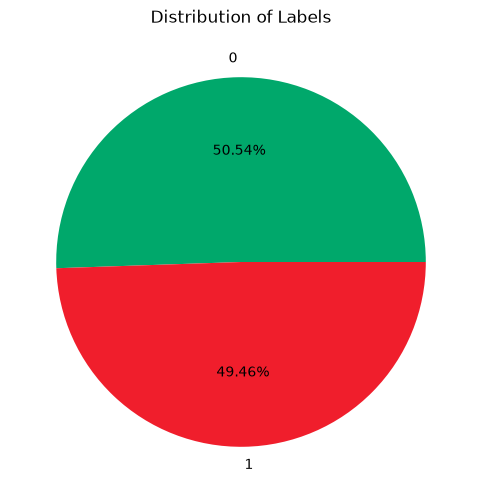

In [9]:
label_counts = df['label'].value_counts()

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(label_counts, labels=label_counts.index, autopct='%1.2f%%', colors=['#00A86B', '#F01E2C'])
plt.title('Distribution of Labels')
plt.show()

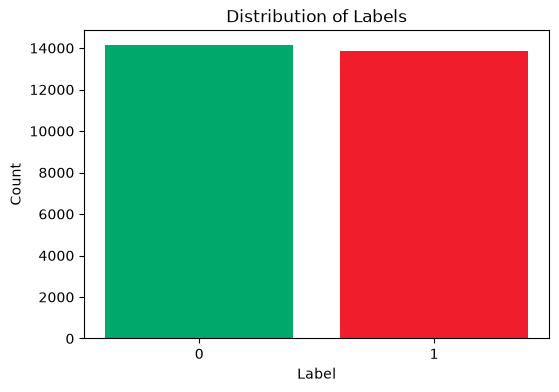

In [10]:
# Bar chart
plt.figure(figsize=(6, 4))
plt.bar(label_counts.index, label_counts.values, color=['#00A86B', '#F01E2C'])
plt.xlabel('Label')
plt.ylabel('Count')
plt.title('Distribution of Labels')
plt.xticks(label_counts.index)  # Ensure x-axis ticks match the labels
plt.show()

In [11]:
def plot_wordcloud(text, title):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.title(title)
    plt.show()

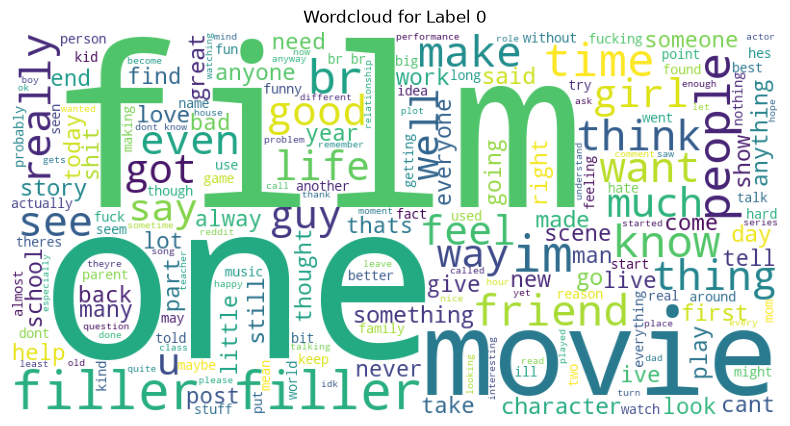

In [12]:
text_label_0 = " ".join(df[df['label'] == 0]['text'].astype(str))
plot_wordcloud(text_label_0, "Wordcloud for Label 0")

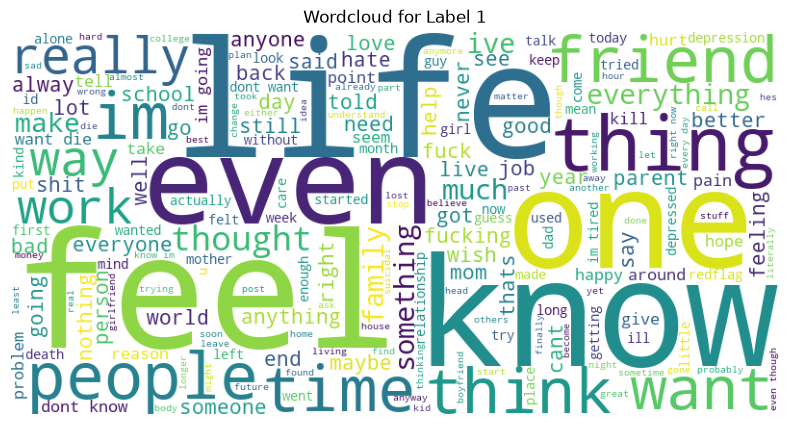

In [13]:
text_label_1 = " ".join(df[df['label'] == 1]['text'].astype(str))
plot_wordcloud(text_label_1, "Wordcloud for Label 1")

In [14]:
def count_words(df):
    word_counts_label_0 = {}
    word_counts_label_1 = {}

    for index, row in df.iterrows():
        text = row['text']
        label = row['label']
        words = word_tokenize(text)

        for word in words:
            word = word.lower()
            if label == 0:
                word_counts_label_0[word] = word_counts_label_0.get(word, 0) + 1
            elif label == 1:
                word_counts_label_1[word] = word_counts_label_1.get(word, 0) + 1

    df_label_0 = pd.DataFrame({'Word': list(word_counts_label_0.keys()), 'Count': list(word_counts_label_0.values())})
    df_label_1 = pd.DataFrame({'Word': list(word_counts_label_1.keys()), 'Count': list(word_counts_label_1.values())})

    df_label_0 = df_label_0.sort_values(by='Count', ascending=False)
    df_label_1 = df_label_1.sort_values(by='Count', ascending=False)

    return df_label_0, df_label_1

In [15]:
df_label_0, df_label_1 = count_words(df)

print("Top Word List for Label 0:\n", df_label_0)

Top Word List for Label 0:
                  Word  Count
18               like   6780
23                 im   6676
206                br   5608
110               one   4548
182              film   3880
...               ...    ...
23699      shotsounds      1
23698      titleheres      1
23697  baseketballits      1
23696  basketballthis      1
49006          ducked      1

[49018 rows x 2 columns]


In [16]:
print("Top Word List for Label 1:\n", df_label_1)

Top Word List for Label 1:
                Word  Count
18               im  28044
10             like  15520
15             want  14944
34             life  12669
9              feel  12660
...             ...    ...
42103     testement      1
42102  individualit      1
42101      lowvalue      1
42100        seclet      1
42099  counsellings      1

[42126 rows x 2 columns]


**Kesimpulan EDA:**

1.   Dataset Mental Health Corpus tidak mempunyai missing value.
2.   Perbandingan kelas label 0 dan 1 hanya 1.08% sehingga dataset ini masih tergolong seimbang.
3.   



In [17]:
# X = df.drop(columns=['label'])
# y = df['label']

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [18]:
# print(f"Train & validation data size: {len(X_train)} ({len(X_train)/len(df)*100:.2f}%)")
# print(f"Test data size: {len(X_test)} ({len(X_test)/len(df)*100:.2f}%)")

**Langkah Data Splitting 1:**
1. Memisahkan kolom label (y) dari fitur (x) agar proses transformasi tidak mempengaruhi label.
2. Split **Train (80%)** dan **Test (20%)**. Data splitting 1 ini bertujuan untuk memisahkan data train dan test terlebih dahulu sebelum memasuki langkah pre-processing atau data cleaning karena data test harus tetap mencerminkan data asli (real-world scenario), jadi tidak boleh dipre-proses terlebih dulu untuk menghindari data leakage, sehingga hanya data train yang akan diproses lebih lanjut.

# Pre-Processing (Data Cleaning)

In [19]:
eng_stopwords = stopwords.words("english")
punctuation_list = string.punctuation
clean_stopwords = {"".join(char for char in word if char not in string.punctuation) for word in eng_stopwords}
stemming = SnowballStemmer("english")
wnl = WordNetLemmatizer()
print(clean_stopwords)

{'off', 'theyd', 'themselves', 'i', 've', 'ain', 'wouldnt', 'shouldve', 'herself', 'hadnt', 'now', 'have', 'hes', 'hers', 'down', 'ill', 'how', 'ours', 'same', 'theyll', 'yourselves', 'hed', 'isn', 'youd', 'above', 'aren', 'such', 'again', 'ma', 'didnt', 'didn', 'yours', 'won', 'those', 'what', 'am', 't', 'under', 'be', 'this', 'a', 'she', 'needn', 'are', 'weren', 'nor', 'an', 'with', 'wont', 'to', 'wasnt', 'each', 'ourselves', 'werent', 'but', 'out', 'm', 'ive', 'him', 'over', 'will', 'arent', 'up', 'thatll', 'where', 'here', 'did', 'we', 'these', 'and', 'her', 'from', 'mightn', 'shouldn', 'myself', 'were', 'into', 'shed', 'shes', 'who', 'mightnt', 'mustn', 'havent', 'the', 'before', 'their', 'so', 'through', 'when', 'at', 'against', 'is', 'yourself', 'd', 'haven', 'he', 'your', 'has', 'shell', 'whom', 'hadn', 'for', 'had', 'hasn', 'during', 'theirs', 'can', 'it', 're', 'doesn', 'about', 'more', 'couldn', 'don', 'isnt', 'only', 'im', 'very', 'itll', 'doing', 'neednt', 'until', 'by', '

In [20]:
print(eng_stopwords)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [21]:
def remove_stopwords(word_list):
  return [word for word in word_list if word not in eng_stopwords]

In [22]:
def remove_clean_stopwords(word_list):
  return [word for word in word_list if word not in clean_stopwords]

In [23]:
def remove_punctuation_numbers(word_list):
  return [word for word in word_list if word.isalpha()]

In [24]:
def stemming_word(word_list):
  return [stemming.stem(word) for word in word_list]

In [25]:
def get_tag(tag):
  if tag in ('JJ', 'JJR', 'JJS'):
    return 'a'
  elif tag in ('NN', 'NNS', 'NNP', 'NNPS'):
    return 'n'
  elif tag in ('VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'):
    return 'v'
  elif tag in ('RB', 'RBR', 'RBS'):
    return 'r'
  else:
    return None

In [26]:
def lemmatizing_word(word_list):
  lemma = []
  tagging = pos_tag(word_list)

  for word, tag in tagging:
    label = get_tag(tag.upper())

    if label != None:
      lemma.append(wnl.lemmatize(word, label))
    else:
      lemma.append(wnl.lemmatize(word))

  return lemma

In [27]:
def preprocess_text(text):
  words = word_tokenize(text.lower())
  words = remove_stopwords(words)
  words = remove_clean_stopwords(words)
  words = remove_punctuation_numbers(words)
  words = stemming_word(words)
  words = lemmatizing_word(words)

  return " ".join(words)

In [28]:
clean_texts = []

for text in df["text"].astype(str):
  clean_texts.append(preprocess_text(text))

df["clean_text"] = clean_texts

In [29]:
df[["text", "clean_text"]].head(100)

,text,clean_text
0,dear american teens question dutch person hear...,dear american teen question dutch person hear ...
1,nothing look forward lifei dont many reasons k...,noth look forward lifei mani reason keep go fe...
2,music recommendations im looking expand playli...,music recommend look expand playlist usual gen...
3,im done trying feel betterthe reason im still ...,do tri feel betterth reason still aliv know mu...
4,worried year old girl subject domestic physic...,worri year old girl subject domest physicalmen...
...,...,...
95,weird or im ambivert already tell pretty weird...,weird ambivert alreadi tell pretti weird scena...
96,weeks ago saved friend redflag suspended reddi...,week ago save friend redflag suspend reddit da...
97,emo anything but songs lonely palaye royal iro...,emo anyth song lone palay royal ironi christop...
98,else dobefore begin long post amp hope take ti...,el dobefor begin long post amp hope take time ...


# Data Splitting

In [30]:
X_train, X_test, y_train, y_test = train_test_split(df["clean_text"], df["label"], test_size=0.2, random_state=42, stratify=df["label"])
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42, stratify=y_train) # 0.125 * 0.8 = 0.1

# TF-IDF Vectorization

In [31]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
vectorizer.fit(X_train)
print(len(vectorizer.get_feature_names_out()))

43331


In [32]:
for num_features in [5000, 10000, 20000]:
    tfidf = TfidfVectorizer(max_features=num_features)
    X_train_tfidf = tfidf.fit_transform(X_train)
    print(f"max_features={num_features}, shape={X_train_tfidf.shape}")

max_features=5000, shape=(19583, 5000)


max_features=10000, shape=(19583, 10000)


max_features=20000, shape=(19583, 20000)


In [33]:
tfidf = TfidfVectorizer(max_features=5000)  # Bisa disesuaikan jumlah fitur
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

# Model

In [34]:
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from xgboost import XGBClassifier

svm_model = SVC(probability=True, kernel='linear', random_state=42)
nb_model = MultinomialNB()
xgb_model = XGBClassifier(eval_metric='logloss', random_state=42)

svm_model.fit(X_train_tfidf, y_train)
nb_model.fit(X_train_tfidf, y_train)
xgb_model.fit(X_train_tfidf, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [35]:
from sklearn.ensemble import VotingClassifier

voting_clf = VotingClassifier(
    estimators=[('svm', svm_model), ('nb', nb_model), ('xgb', xgb_model)],
    voting='soft'  # 'soft' untuk probabilitas, 'hard' untuk mayoritas kelas
)

voting_clf.fit(X_train_tfidf, y_train)

VotingClassifier(estimators=[('svm',
                              SVC(kernel='linear', probability=True,
                                  random_state=42)),
                             ('nb', MultinomialNB()),
                             ('xgb',
                              XGBClassifier(base_score=None, booster=None,
                                            callbacks=None,
                                            colsample_bylevel=None,
                                            colsample_bynode=None,
                                            colsample_bytree=None, device=None,
                                            early_stopping_rounds=None,
                                            enable_categorical=False,
                                            eval_metric='logloss',
                                            feature_types=None...
                                            grow_policy=None,
                                            importance_type=None,
                                            interaction_constraints=None,
                                            learning_rate=None, max_bin=None,
                                            max_cat_threshold=None,
                                            max_cat_to_onehot=None,
                                            max_delta_step=None, max_depth=None,
                                            max_leaves=None,
                                            min_child_weight=None, missing=nan,
                                            monotone_constraints=None,
                                            multi_strategy=None,
                                            n_estimators=None, n_jobs=None,
                                            num_parallel_tree=None, ...))],
                 voting='soft')

In [36]:
from sklearn.metrics import accuracy_score, classification_report

y_val_pred = voting_clf.predict(X_val_tfidf)
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.9245889921372409
              precision    recall  f1-score   support

           0       0.94      0.91      0.92      1414
           1       0.91      0.94      0.92      1384

    accuracy                           0.92      2798
   macro avg       0.92      0.92      0.92      2798
weighted avg       0.92      0.92      0.92      2798



In [37]:
y_test_pred = voting_clf.predict(X_test_tfidf)
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))

Test Accuracy: 0.9226233023588277
              precision    recall  f1-score   support

           0       0.93      0.92      0.92      2828
           1       0.92      0.93      0.92      2768

    accuracy                           0.92      5596
   macro avg       0.92      0.92      0.92      5596
weighted avg       0.92      0.92      0.92      5596

